# District-wise IPC Crime Analysis in India (2001–2012)

## Notebook 3 : Exploratory Data Analysis


In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_csv("crime_cleaned_2001_2012.csv")

In [3]:
df.head()

,STATE_UT,DISTRICT,YEAR,MURDER,ATTEMPT_TO_MURDER,CULPABLE_HOMICIDE_NOT_AMOUNTING_TO_MURDER,RAPE,CUSTODIAL_RAPE,OTHER_RAPE,KIDNAPPING_AND_ABDUCTION,KIDNAPPING_AND_ABDUCTION_OF_WOMEN_AND_GIRLS,KIDNAPPING_AND_ABDUCTION_OF_OTHERS,DACOITY,PREPARATION_AND_ASSEMBLY_FOR_DACOITY,ROBBERY,BURGLARY,THEFT,AUTO_THEFT,OTHER_THEFT,RIOTS,CRIMINAL_BREACH_OF_TRUST,CHEATING,COUNTERFIETING,ARSON,HURT_GREVIOUS_HURT,DOWRY_DEATHS,ASSAULT_ON_WOMEN_WITH_INTENT_TO_OUTRAGE_HER_MODESTY,INSULT_TO_MODESTY_OF_WOMEN,CRUELTY_BY_HUSBAND_OR_HIS_RELATIVES,IMPORTATION_OF_GIRLS_FROM_FOREIGN_COUNTRIES,CAUSING_DEATH_BY_NEGLIGENCE,OTHER_IPC_CRIMES,TOTAL_IPC_CRIMES
0,ANDHRA PRADESH,ADILABAD,2001,101,60,17,50,0,50,46,30,16,9,0,41,198,199,22,177,78,16,104,1,30,1131,16,149,34,175,0,181,1518,4154
1,ANDHRA PRADESH,ANANTAPUR,2001,151,125,1,23,0,23,53,30,23,8,0,16,191,366,57,309,168,11,65,8,69,1543,7,118,24,154,0,270,754,4125
2,ANDHRA PRADESH,CHITTOOR,2001,101,57,2,27,0,27,59,34,25,4,0,14,237,723,164,559,156,33,209,9,38,2088,14,112,83,186,0,404,1262,5818
3,ANDHRA PRADESH,CUDDAPAH,2001,80,53,1,20,0,20,25,20,5,1,0,4,98,173,36,137,164,12,37,2,23,795,17,126,38,57,0,233,1181,3140
4,ANDHRA PRADESH,EAST GODAVARI,2001,82,67,1,23,0,23,49,26,23,4,0,25,437,1021,150,871,70,50,220,3,41,1244,12,109,58,247,0,431,2313,6507


In [4]:
df.shape

(8597, 33)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8597 entries, 0 to 8596
Data columns (total 33 columns):
 #   Column                                               Non-Null Count  Dtype 
---  ------                                               --------------  ----- 
 0   STATE_UT                                             8597 non-null   object
 1   DISTRICT                                             8597 non-null   object
 2   YEAR                                                 8597 non-null   int64 
 3   MURDER                                               8597 non-null   int64 
 4   ATTEMPT_TO_MURDER                                    8597 non-null   int64 
 5   CULPABLE_HOMICIDE_NOT_AMOUNTING_TO_MURDER            8597 non-null   int64 
 6   RAPE                                                 8597 non-null   int64 
 7   CUSTODIAL_RAPE                                       8597 non-null   int64 
 8   OTHER_RAPE                                           8597 non-null   int64 
 9

In [6]:
df.describe()

,YEAR,MURDER,ATTEMPT_TO_MURDER,CULPABLE_HOMICIDE_NOT_AMOUNTING_TO_MURDER,RAPE,CUSTODIAL_RAPE,OTHER_RAPE,KIDNAPPING_AND_ABDUCTION,KIDNAPPING_AND_ABDUCTION_OF_WOMEN_AND_GIRLS,KIDNAPPING_AND_ABDUCTION_OF_OTHERS,DACOITY,PREPARATION_AND_ASSEMBLY_FOR_DACOITY,ROBBERY,BURGLARY,THEFT,AUTO_THEFT,OTHER_THEFT,RIOTS,CRIMINAL_BREACH_OF_TRUST,CHEATING,COUNTERFIETING,ARSON,HURT_GREVIOUS_HURT,DOWRY_DEATHS,ASSAULT_ON_WOMEN_WITH_INTENT_TO_OUTRAGE_HER_MODESTY,INSULT_TO_MODESTY_OF_WOMEN,CRUELTY_BY_HUSBAND_OR_HIS_RELATIVES,IMPORTATION_OF_GIRLS_FROM_FOREIGN_COUNTRIES,CAUSING_DEATH_BY_NEGLIGENCE,OTHER_IPC_CRIMES,TOTAL_IPC_CRIMES
count,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000,8597.000000
mean,2006.635338,46.823659,40.941840,5.189485,27.816331,0.003024,27.813307,41.509480,30.697569,10.811911,6.910434,3.715366,28.878330,129.968477,407.180412,147.768989,259.411423,90.139235,21.405258,89.286612,3.107828,13.226009,392.215424,10.608584,52.710829,14.429917,101.803071,0.103757,116.536466,1140.261603,2784.768408
std,3.464064,42.755817,50.589877,9.948005,30.897866,0.079201,30.893890,56.062152,42.502686,21.318741,10.945607,15.282460,50.937364,195.396249,778.770851,370.844951,467.582754,137.592242,36.905319,183.973214,8.116195,30.415132,559.583270,14.186601,64.912227,43.144466,180.073942,1.433148,155.590836,1438.819352,3068.017393
min,2001.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2004.000000,18.000000,10.000000,0.000000,8.000000,0.000000,8.000000,9.000000,6.000000,1.000000,1.000000,0.000000,6.000000,29.000000,86.000000,11.000000,62.000000,10.000000,3.000000,12.000000,0.000000,2.000000,40.000000,1.000000,9.000000,0.000000,11.000000,0.000000,5.000000,255.000000,835.000000
50%,2007.000000,37.000000,27.000000,2.000000,19.000000,0.000000,19.000000,24.000000,17.000000,5.000000,3.000000,0.000000,16.000000,79.000000,206.000000,45.000000,145.000000,44.000000,11.000000,35.000000,1.000000,8.000000,191.000000,5.000000,30.000000,2.000000,46.000000,0.000000,65.000000,715.000000,2011.000000
75%,2010.000000,63.000000,54.000000,5.000000,39.000000,0.000000,39.000000,52.000000,39.000000,12.000000,9.000000,2.000000,34.000000,164.000000,430.000000,127.000000,291.000000,116.000000,25.000000,93.000000,3.000000,18.000000,490.000000,15.000000,71.000000,12.000000,126.000000,0.000000,166.000000,1528.000000,3789.000000
max,2012.000000,542.000000,741.000000,241.000000,568.000000,5.000000,568.000000,587.000000,492.000000,484.000000,219.000000,470.000000,1131.000000,3175.000000,13195.000000,7074.000000,9028.000000,3181.000000,589.000000,3155.000000,170.000000,2350.000000,4837.000000,168.000000,621.000000,1257.000000,3035.000000,60.000000,2058.000000,32452.000000,34638.000000


## Univariate Analysis

### Total States

In [7]:
df["STATE_UT"].nunique()

35

### Total Disrtict

In [8]:
df["DISTRICT"].nunique()

806

### Total Years

In [10]:
sorted(df["YEAR"].unique())

[np.int64(2001),
 np.int64(2002),
 np.int64(2003),
 np.int64(2004),
 np.int64(2005),
 np.int64(2006),
 np.int64(2007),
 np.int64(2008),
 np.int64(2009),
 np.int64(2010),
 np.int64(2011),
 np.int64(2012)]

### Distribution of Total IPC Crimes

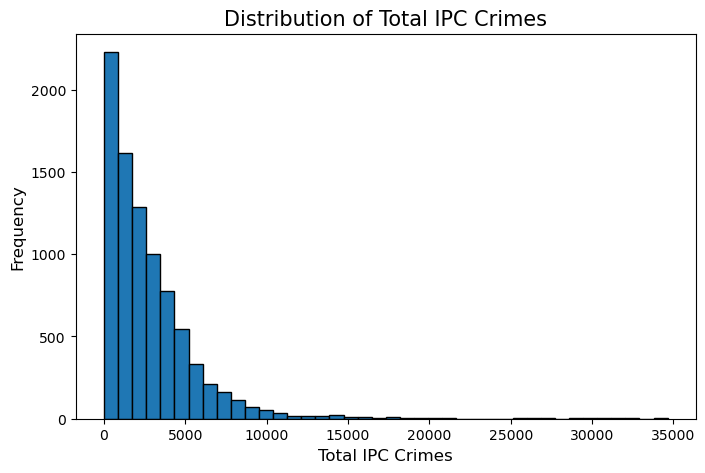


Most districts report relatively low crime counts,while a smaller number of districts report very high crime levels, indicating a right-skewed distribution.


In [28]:
plt.figure(figsize=(8,5))

plt.hist(df["TOTAL_IPC_CRIMES"], bins=40,edgecolor='black')

plt.title("Distribution of Total IPC Crimes",fontsize=15,color='black',style='normal')

plt.xlabel("Total IPC Crimes",fontsize=12,color='black')

plt.ylabel("Frequency",fontsize=12,color='black')

plt.show()
print("\nMost districts report relatively low crime counts,while a smaller number of districts report very high crime levels, indicating a right-skewed distribution.")

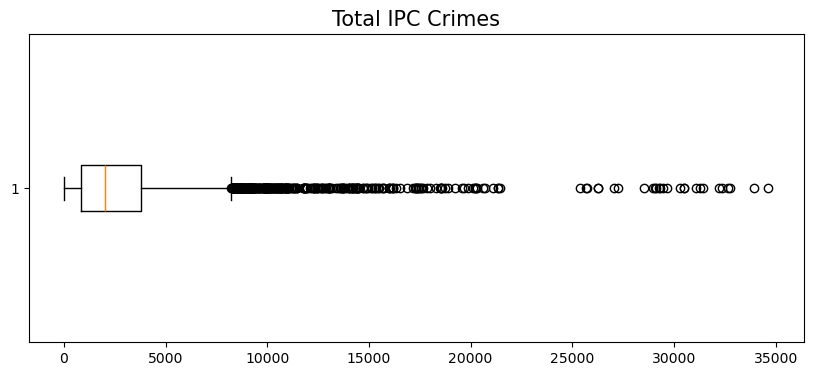


The dataset contains several high-value outliers representing districts with significantly higher reported crimes.


In [33]:
plt.figure(figsize=(10,4))

plt.boxplot(df["TOTAL_IPC_CRIMES"], vert=False)

plt.title("Total IPC Crimes",fontsize=15,color='black')

plt.show()

print('\nThe dataset contains several high-value outliers representing districts with significantly higher reported crimes.')

## State Analysis

### Which States report the highest crimes?

In [53]:
state_crime = (
    df.groupby("STATE_UT", as_index=False)["TOTAL_IPC_CRIMES"]
      .sum()
      .sort_values(by="TOTAL_IPC_CRIMES", ascending=False)
      .head(10)
)

state_crime

,STATE_UT,TOTAL_IPC_CRIMES
19,MADHYA PRADESH,2413770
20,MAHARASHTRA,2273436
30,TAMIL NADU,2060176
1,ANDHRA PRADESH,2018981
32,UTTAR PRADESH,1858074
28,RAJASTHAN,1855916
16,KARNATAKA,1481063
17,KERALA,1437459
11,GUJARAT,1385775
4,BIHAR,1346293


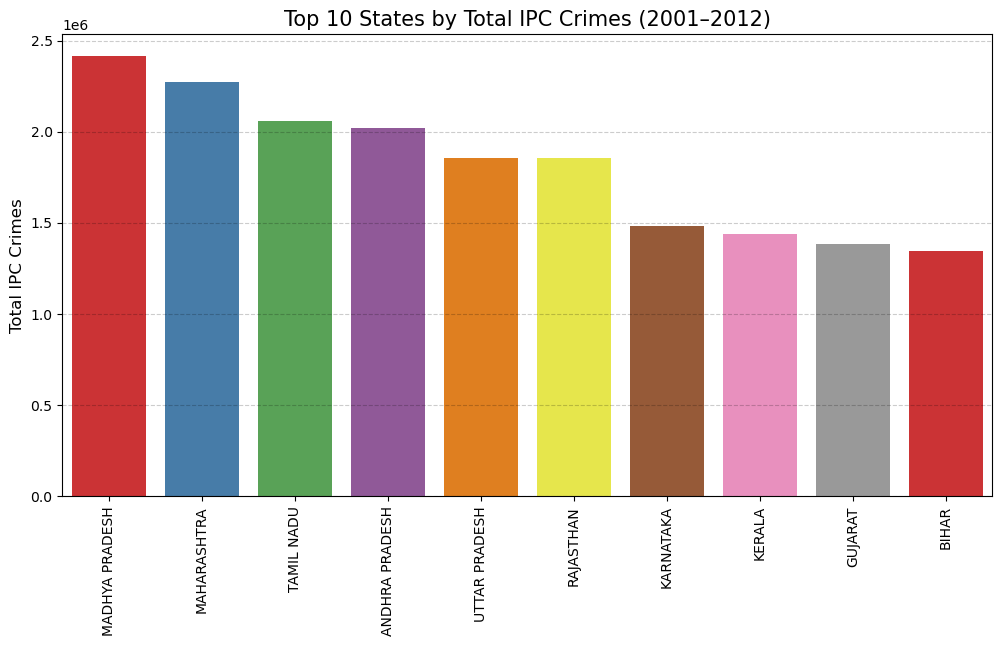


The top 10 states contribute to share of the total reported IPC crimes during 2001–2012.


In [142]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=state_crime,
    x="STATE_UT",
    y="TOTAL_IPC_CRIMES",
    hue='STATE_UT',
    palette="Set1"
)

plt.title("Top 10 States by Total IPC Crimes (2001–2012)",fontsize=15,color='black')
plt.xlabel(None)
plt.ylabel("Total IPC Crimes",fontsize=12,color='black')
plt.xticks(rotation=90)

plt.grid(linestyle='dashed',axis='y',alpha=0.2,color='black')
plt.show()

print('\nThe top 10 states contribute to share of the total reported IPC crimes during 2001–2012.')

### District Analysis

In [67]:
district_crime = (
    df.groupby("DISTRICT",as_index=False)["TOTAL_IPC_CRIMES"]
      .sum()
      .sort_values(by='TOTAL_IPC_CRIMES',ascending=False).head(10)
)

district_crime

,DISTRICT,TOTAL_IPC_CRIMES
61,BANGALORE COMMR.,350347
504,MUMBAI COMMR.,222670
5,AHMEDABAD COMMR.,218005
312,INDORE,204398
304,HYDERABAD CITY,202931
100,BHOPAL,169575
145,CHENNAI,164467
422,KOLKATA,158429
574,PATNA,147542
503,MUMBAI,141815


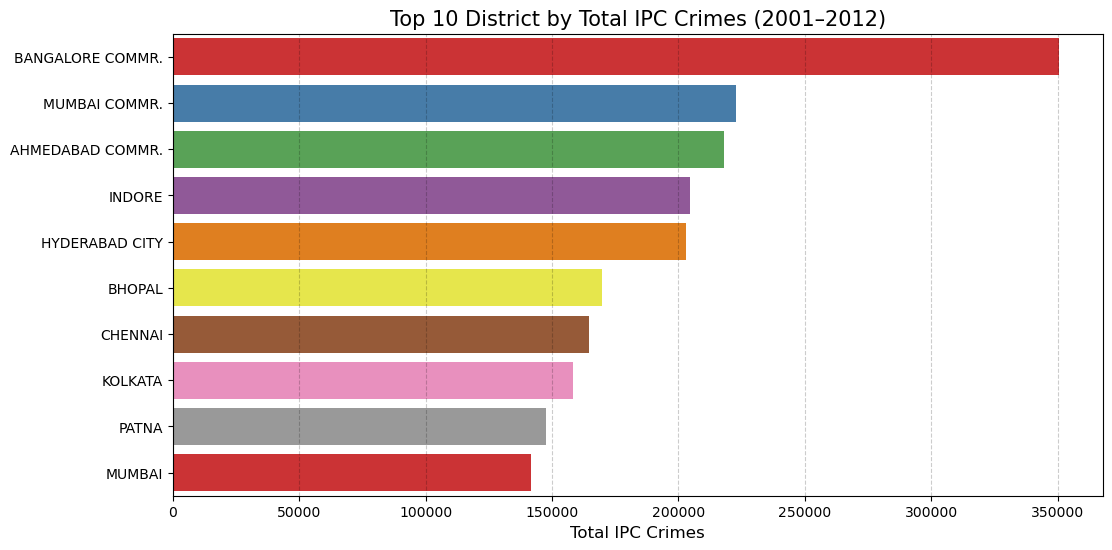

In [141]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=district_crime,
    y="DISTRICT",
    x="TOTAL_IPC_CRIMES",
    hue='DISTRICT',
    palette="Set1"
)



plt.title("Top 10 District by Total IPC Crimes (2001–2012)",fontsize=15,color='black')
plt.ylabel(None)
plt.xlabel("Total IPC Crimes",fontsize=12,color='black')
plt.xticks(rotation=360)

plt.grid(linestyle='dashed',axis='x',alpha=0.2,color='black')
plt.show()


### Year-wise Trend
     How has crime changed over time?

In [72]:
yearly = (
    df.groupby("YEAR")["TOTAL_IPC_CRIMES"]
      .sum()
)

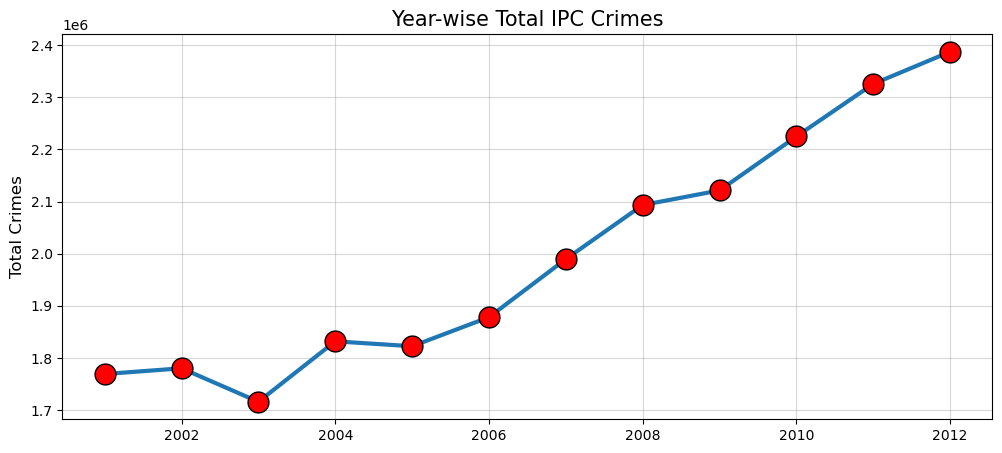


Analyze whether crimes increased, decreased, or remained relatively stable across the years.


In [116]:
yearly.plot(
    marker="o",
    mfc='red',
    mec='black',
    ms=15,
    linewidth=3,
    figsize=(12,5)
)

plt.title("Year-wise Total IPC Crimes",fontsize=15,color='black')

plt.xlabel(None)
plt.ylabel("Total Crimes",fontsize=12,color='black')

plt.grid(True,alpha=0.5)

plt.show()

print('\nAnalyze whether crimes increased, decreased, or remained relatively stable across the years.')

## Crime Category Analysis
    Most Reported Crime Category

In [82]:
crime_columns = df.columns[3:-1]

crime_totals = (
    df[crime_columns]
      .sum()
      .sort_values(ascending=False)
)

crime_totals.head(10)

OTHER_IPC_CRIMES                       9802829
THEFT                                  3500530
HURT_GREVIOUS_HURT                     3371876
OTHER_THEFT                            2230160
AUTO_THEFT                             1270370
BURGLARY                               1117339
CAUSING_DEATH_BY_NEGLIGENCE            1001864
CRUELTY_BY_HUSBAND_OR_HIS_RELATIVES     875201
RIOTS                                   774927
CHEATING                                767597
dtype: int64

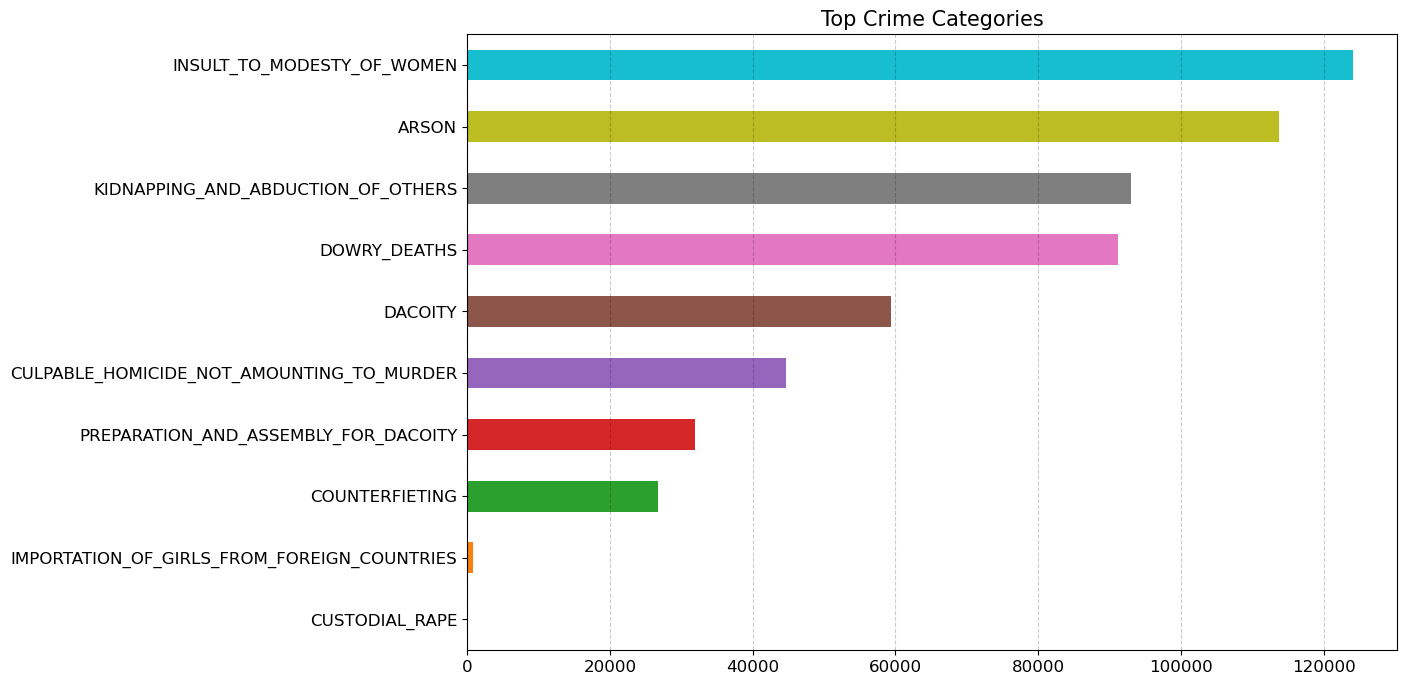

In [143]:
crime_columns = df.columns[3:-1]

crime_totals = (
    df[crime_columns]
      .sum()
      .sort_values()
)

colors = plt.cm.tab10(np.linspace(0, 1, 10))

crime_totals.head(10).plot(
    kind="barh",
    figsize=(12,8),
    color=colors
)

plt.title("Top Crime Categories",fontsize=15,color='black')

plt.xticks(fontsize=12,color='black',)
plt.yticks(fontsize=12,color='black',)

plt.grid(linestyle='dashed',axis='x',alpha=0.2,color='black')
plt.show()

### Correlation Analysis

In [84]:
corr = df.corr(numeric_only=True)

corr["TOTAL_IPC_CRIMES"].sort_values(ascending=False)

TOTAL_IPC_CRIMES                                       1.000000
OTHER_IPC_CRIMES                                       0.868976
THEFT                                                  0.804406
BURGLARY                                               0.804024
OTHER_THEFT                                            0.768103
CHEATING                                               0.726677
AUTO_THEFT                                             0.720776
HURT_GREVIOUS_HURT                                     0.717801
ROBBERY                                                0.652492
ASSAULT_ON_WOMEN_WITH_INTENT_TO_OUTRAGE_HER_MODESTY    0.646243
CRIMINAL_BREACH_OF_TRUST                               0.618263
CRUELTY_BY_HUSBAND_OR_HIS_RELATIVES                    0.587741
MURDER                                                 0.571607
CAUSING_DEATH_BY_NEGLIGENCE                            0.566771
COUNTERFIETING                                         0.536897
OTHER_RAPE                              

### Observation
    Theft has a strong positive correlation with Total IPC Crimes. Districts reporting higher theft incidents also tend to report higher overall IPC crimes. This indicates that theft is one of the major contributors to the overall crime burden.

# Key Insights

- State Madhya Pradesh recorded the highest total IPC crimes during the analysis period.
- District Bengalore Commr consistently reported the highest crime counts.
- Total IPC crimes showed an increasing/decreasing trend across the years.
- Theft and burglary were among the largest contributors to overall IPC crimes.
- Crime distribution is highly skewed, with a few districts accounting for disproportionately high totals.